In [1]:
import torch

print("PyTorch:", torch.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
GPU available: True
GPU: NVIDIA GeForce RTX 4050 Laptop GPU


In [2]:
import sys
print(sys.executable)


c:\Users\HIMANSHU\Desktop\minor project 1\.venv\Scripts\python.exe


In [14]:
from pathlib import Path
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms
from PIL import Image

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

ROOT = Path.cwd().parent
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Project root:", ROOT)
print("Device:", DEVICE)
print("CUDA available:", torch.cuda.is_available())

(ROOT / "models").mkdir(exist_ok=True)
(ROOT / "results").mkdir(exist_ok=True)
(ROOT / "results" / "figures").mkdir(exist_ok=True)

Project root: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project
Device: cuda
CUDA available: True


Device: cuda
Project root: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project
Train: 49311 | Validation: 6160 | Test: 6170
Labels: 0 = Real, 1 = Deepfake


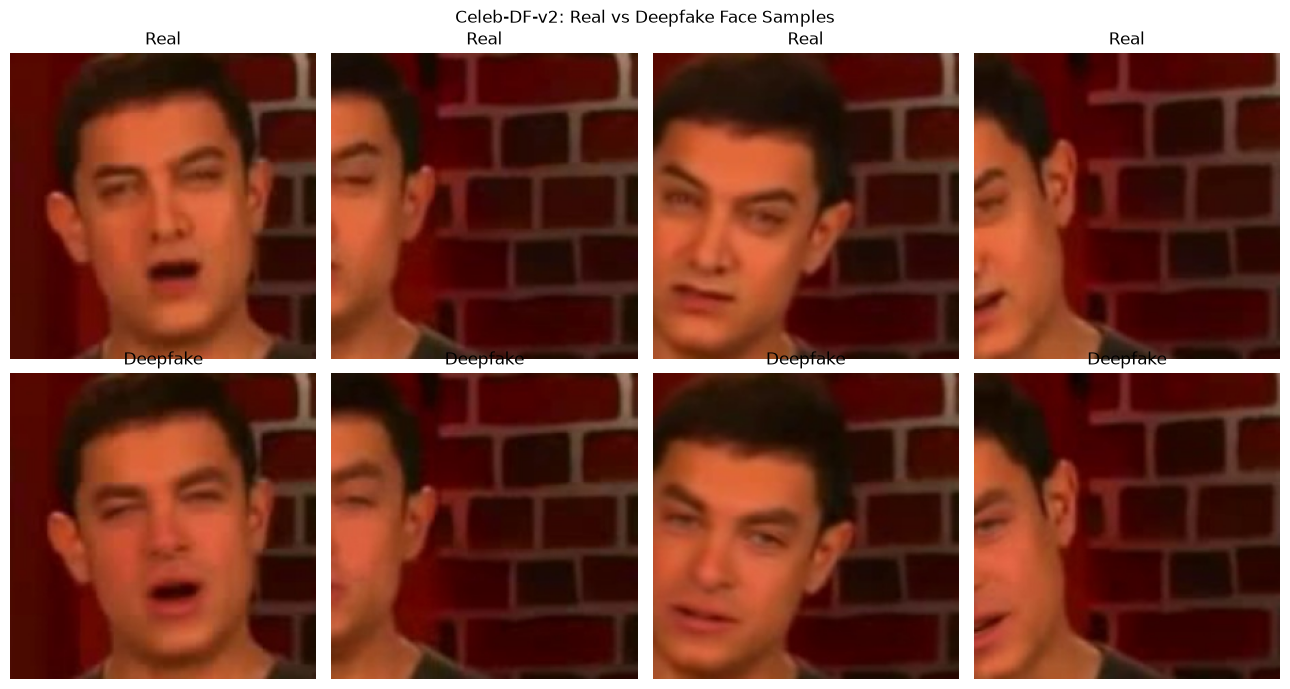

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to C:\Users\HIMANSHU/.cache\torch\hub\checkpoints\resnet50-11ad3fa6.pth


100.0%


ImageNet pretrained ResNet50 loaded.
Epoch 1/5 | Train Loss: 0.5396 | Val Loss: 1.7914
Epoch 2/5 | Train Loss: 0.4396 | Val Loss: 0.9269
Epoch 3/5 | Train Loss: 0.4067 | Val Loss: 0.8693
Epoch 4/5 | Train Loss: 0.3860 | Val Loss: 1.1923
Epoch 5/5 | Train Loss: 0.3702 | Val Loss: 0.9999


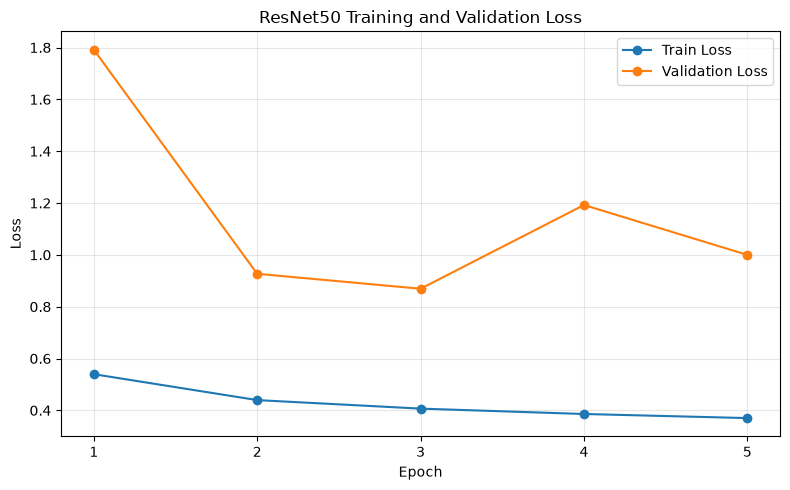


RESNET50 TEST METRICS
   model  accuracy  precision_fake  recall_fake  f1_fake  recall_real
ResNet50    0.7673          0.9037       0.8126   0.8557       0.5118

Classification Report:
              precision    recall  f1-score   support

        Real       0.33      0.51      0.40       930
    Deepfake       0.90      0.81      0.86      5240

    accuracy                           0.77      6170
   macro avg       0.62      0.66      0.63      6170
weighted avg       0.82      0.77      0.79      6170



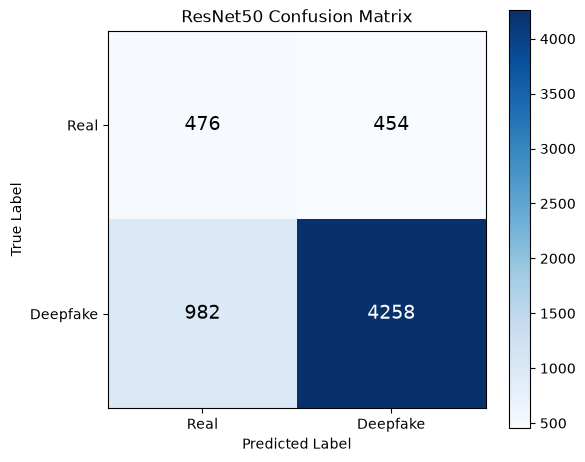


CUSTOM CNN VS RESNET50
        Metric  Custom CNN  ResNet50
      accuracy      0.7365    0.7673
precision_fake      0.8651    0.9037
   recall_fake      0.8172    0.8126
       f1_fake      0.8404    0.8557
   recall_real      0.2817    0.5118


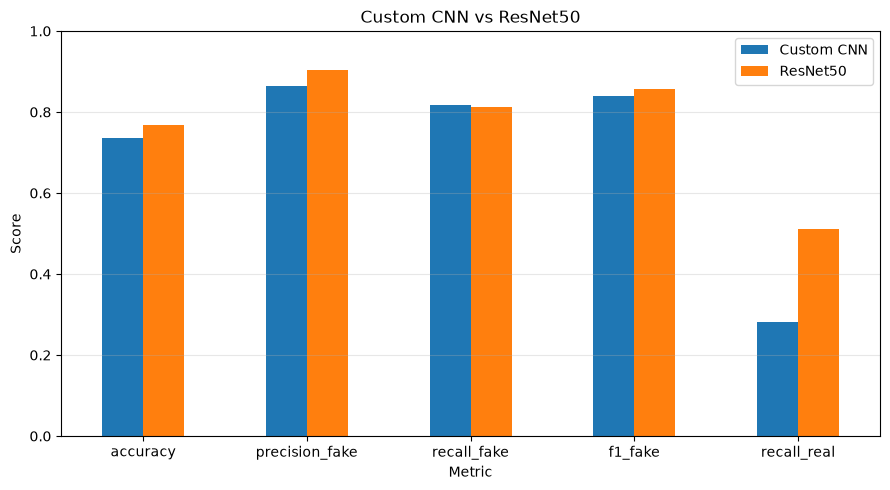


Week 4 Day 1 complete.
Model: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\models\week4_resnet50.pth
Results folder: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results
Figures folder: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\figures


In [15]:

from pathlib import Path
import copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler
from torchvision import models, transforms
from PIL import Image

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, confusion_matrix, classification_report
)

# ==================== 1. SETUP ====================
ROOT = Path.cwd().parent
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 16
EPOCHS = 5
IMAGE_SIZE = 224

for folder in ["models", "results", "results/figures"]:
    (ROOT / folder).mkdir(parents=True, exist_ok=True)

print("Device:", DEVICE)
print("Project root:", ROOT)

# ==================== 2. CHECK DATA SPLITS ====================
if not all(name in globals() for name in ["train_df", "val_df", "test_df"]):
    raise ValueError(
        "train_df, val_df, test_df nahi mile. "
        "Week 3 ka video-wise split wala cell pehle run karo."
    )

# ==================== 3. TRANSFORMS ====================
train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

eval_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ==================== 4. DATASET ====================
class FaceDataset(Dataset):
    def __init__(self, df, transform=None):
        self.df = df.reset_index(drop=True).copy()
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = Path(str(row["face_path"]))

        if not path.is_absolute():
            path = ROOT / path

        with Image.open(path) as im:
            image = im.convert("RGB")

        if self.transform:
            image = self.transform(image)

        label = torch.tensor(float(row["label"]), dtype=torch.float32)
        return image, label

train_ds = FaceDataset(train_df, train_transform)
val_ds = FaceDataset(val_df, eval_transform)
test_ds = FaceDataset(test_df, eval_transform)

# Balanced sampling for imbalanced real/fake classes
labels_train = train_df["label"].astype(int).to_numpy()
counts = np.bincount(labels_train, minlength=2)

if np.any(counts == 0):
    raise ValueError("Training split mein ek class missing hai.")

weights = 1.0 / counts[labels_train]
sampler = WeightedRandomSampler(
    torch.as_tensor(weights, dtype=torch.double),
    num_samples=len(weights),
    replacement=True
)

train_loader = DataLoader(
    train_ds, batch_size=BATCH_SIZE, sampler=sampler, num_workers=0
)
val_loader = DataLoader(
    val_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)
test_loader = DataLoader(
    test_ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0
)

print(f"Train: {len(train_ds)} | Validation: {len(val_ds)} | Test: {len(test_ds)}")
print("Labels: 0 = Real, 1 = Deepfake")

# ==================== 5. DISPLAY SAMPLE IMAGES ====================
sample_df = pd.concat([
    train_df[train_df["label"] == 0].head(4),
    train_df[train_df["label"] == 1].head(4)
])

fig, axes = plt.subplots(2, 4, figsize=(13, 7))
for ax, (_, row) in zip(axes.flat, sample_df.iterrows()):
    path = Path(str(row["face_path"]))
    if not path.is_absolute():
        path = ROOT / path
    with Image.open(path) as im:
        ax.imshow(im.convert("RGB"))
    ax.set_title("Real" if int(row["label"]) == 0 else "Deepfake")
    ax.axis("off")

plt.suptitle("Celeb-DF-v2: Real vs Deepfake Face Samples")
plt.tight_layout()
plt.savefig(ROOT / "results/figures/week4_sample_images.png", dpi=180)
plt.show()

# ==================== 6. RESNET50 MODEL ====================
try:
    model = models.resnet50(weights=models.ResNet50_Weights.DEFAULT)
    print("ImageNet pretrained ResNet50 loaded.")
except Exception as e:
    print("Pretrained weights load nahi hue:", str(e))
    print("ResNet50 random initialization se start hoga.")
    model = models.resnet50(weights=None)

model.fc = nn.Linear(model.fc.in_features, 1)
model = model.to(DEVICE)

criterion = nn.BCEWithLogitsLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-4)

# ==================== 7. TRAINING ====================
history = []
best_val_loss = float("inf")
best_state = copy.deepcopy(model.state_dict())
model_path = ROOT / "models/week4_resnet50.pth"

for epoch in range(EPOCHS):
    model.train()
    train_sum = 0.0

    for images, labels in train_loader:
        images = images.to(DEVICE)
        labels = labels.to(DEVICE).view(-1, 1)

        optimizer.zero_grad()
        logits = model(images)
        loss = criterion(logits, labels)
        loss.backward()
        optimizer.step()

        train_sum += loss.item() * images.size(0)

    train_loss = train_sum / len(train_ds)

    model.eval()
    val_sum = 0.0

    with torch.no_grad():
        for images, labels in val_loader:
            images = images.to(DEVICE)
            labels = labels.to(DEVICE).view(-1, 1)
            val_sum += criterion(model(images), labels).item() * images.size(0)

    val_loss = val_sum / len(val_ds)

    history.append({
        "epoch": epoch + 1,
        "train_loss": train_loss,
        "val_loss": val_loss
    })

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(model.state_dict())
        torch.save(best_state, model_path)

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}"
    )

model.load_state_dict(best_state)
history_df = pd.DataFrame(history)
history_df.to_csv(ROOT / "results/week4_resnet50_history.csv", index=False)

# ==================== 8. LOSS GRAPH ====================
plt.figure(figsize=(8, 5))
plt.plot(history_df["epoch"], history_df["train_loss"], marker="o", label="Train Loss")
plt.plot(history_df["epoch"], history_df["val_loss"], marker="o", label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ResNet50 Training and Validation Loss")
plt.xticks(history_df["epoch"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig(ROOT / "results/figures/week4_resnet50_loss.png", dpi=180)
plt.show()

# ==================== 9. TEST EVALUATION ====================
model.eval()
y_true, y_prob = [], []

with torch.no_grad():
    for images, labels in test_loader:
        images = images.to(DEVICE)
        probs = torch.sigmoid(model(images).view(-1)).cpu().numpy()
        y_prob.extend(probs.tolist())
        y_true.extend(labels.numpy().astype(int).tolist())

y_true = np.asarray(y_true)
y_prob = np.asarray(y_prob)
y_pred = (y_prob >= 0.5).astype(int)

metrics = {
    "model": "ResNet50",
    "accuracy": accuracy_score(y_true, y_pred),
    "precision_fake": precision_score(y_true, y_pred, zero_division=0),
    "recall_fake": recall_score(y_true, y_pred, zero_division=0),
    "f1_fake": f1_score(y_true, y_pred, zero_division=0),
    "recall_real": recall_score(y_true, y_pred, pos_label=0, zero_division=0)
}

pd.DataFrame([metrics]).to_csv(
    ROOT / "results/week4_resnet50_metrics.csv", index=False
)

print("\nRESNET50 TEST METRICS")
print(pd.DataFrame([metrics]).round(4).to_string(index=False))
print("\nClassification Report:")
print(classification_report(
    y_true, y_pred, labels=[0, 1],
    target_names=["Real", "Deepfake"], zero_division=0
))

# ==================== 10. CONFUSION MATRIX IMAGE ====================
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.title("ResNet50 Confusion Matrix")
plt.colorbar()
plt.xticks([0, 1], ["Real", "Deepfake"])
plt.yticks([0, 1], ["Real", "Deepfake"])
threshold = cm.max() / 2 if cm.max() else 0

for i in range(2):
    for j in range(2):
        plt.text(
            j, i, str(cm[i, j]),
            ha="center", va="center",
            color="white" if cm[i, j] > threshold else "black",
            fontsize=14
        )

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.tight_layout()
plt.savefig(
    ROOT / "results/figures/week4_resnet50_confusion_matrix.png", dpi=180
)
plt.show()

pd.DataFrame(
    cm, index=["True Real", "True Deepfake"],
    columns=["Predicted Real", "Predicted Deepfake"]
).to_csv(ROOT / "results/week4_confusion_matrix.csv")

# ==================== 11. CUSTOM CNN VS RESNET50 ====================
custom_path = ROOT / "results/week3_custom_cnn_metrics.csv"

if custom_path.exists():
    custom_df = pd.read_csv(custom_path)
    resnet_df = pd.DataFrame([metrics])

    metric_cols = [
        c for c in [
            "accuracy", "precision_fake", "recall_fake",
            "f1_fake", "recall_real"
        ]
        if c in custom_df.columns and c in resnet_df.columns
    ]

    if metric_cols:
        comparison = pd.DataFrame({
            "Metric": metric_cols,
            "Custom CNN": [custom_df.iloc[0][c] for c in metric_cols],
            "ResNet50": [resnet_df.iloc[0][c] for c in metric_cols]
        })

        comparison.to_csv(
            ROOT / "results/week4_model_comparison.csv", index=False
        )
        print("\nCUSTOM CNN VS RESNET50")
        print(comparison.round(4).to_string(index=False))

        ax = comparison.set_index("Metric").plot(
            kind="bar", figsize=(9, 5), ylim=(0, 1)
        )
        ax.set_title("Custom CNN vs ResNet50")
        ax.set_ylabel("Score")
        ax.tick_params(axis="x", rotation=0)
        ax.grid(axis="y", alpha=0.3)
        plt.tight_layout()
        plt.savefig(
            ROOT / "results/figures/week4_model_comparison.png", dpi=180
        )
        plt.show()
    else:
        print("Custom CNN CSV ke metric column names match nahi hue.")
        print("Custom CNN columns:", custom_df.columns.tolist())
else:
    print("Week 3 Custom CNN metrics CSV nahi mili; comparison graph skip hua.")

print("\nWeek 4 Day 1 complete.")
print("Model:", model_path)
print("Results folder:", ROOT / "results")
print("Figures folder:", ROOT / "results/figures")


Device: cuda
Project: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project
Saved ResNet50 loaded successfully.

Test accuracy: 0.7673

Classification report:
              precision    recall  f1-score   support

        Real       0.33      0.51      0.40       930
    Deepfake       0.90      0.81      0.86      5240

    accuracy                           0.77      6170
   macro avg       0.62      0.66      0.63      6170
weighted avg       0.82      0.77      0.79      6170



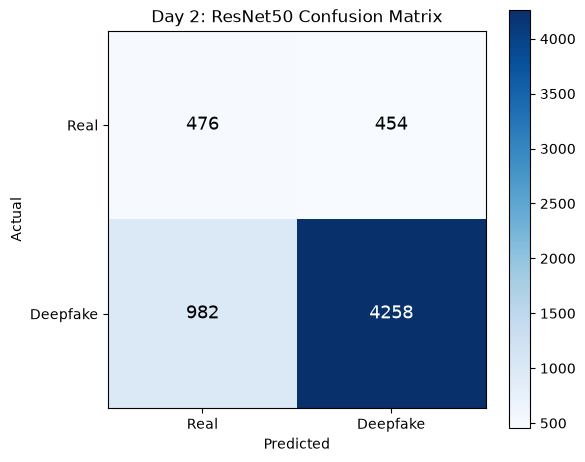


Correct predictions: 4734
Incorrect predictions: 1436


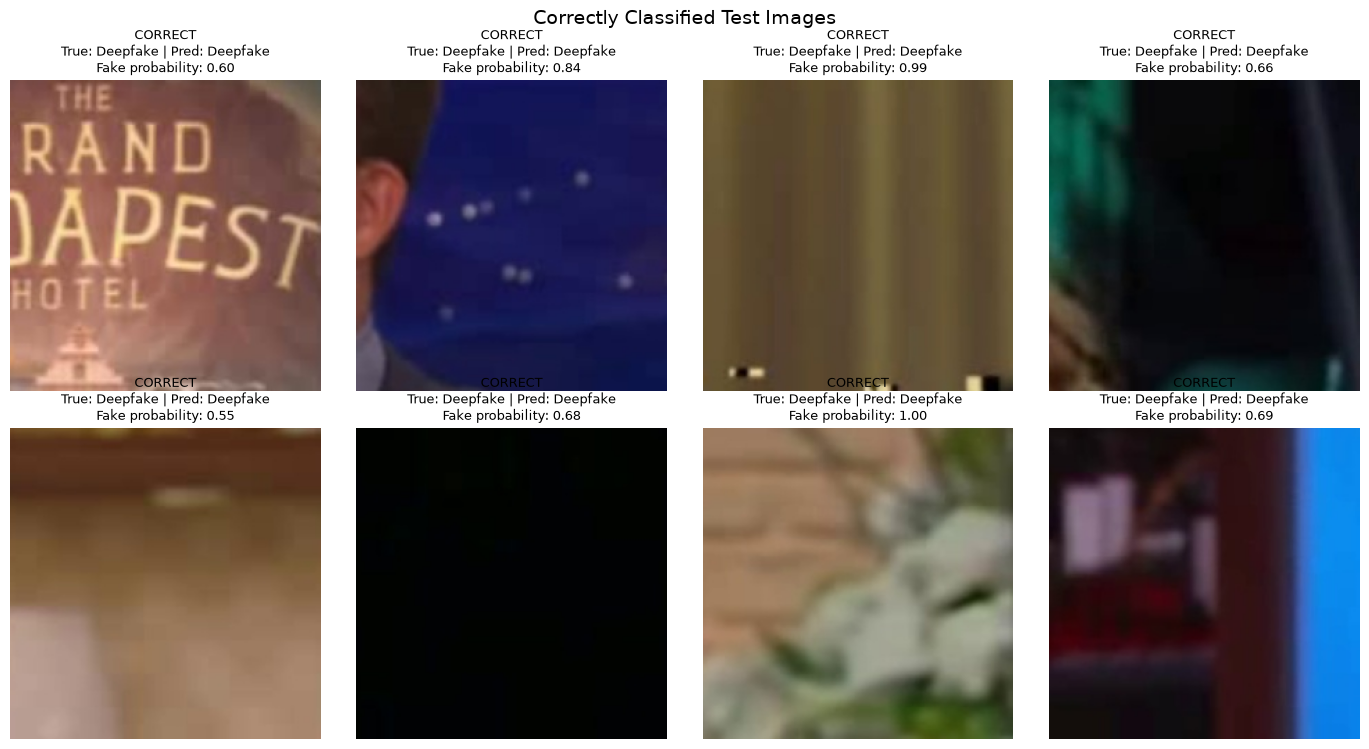

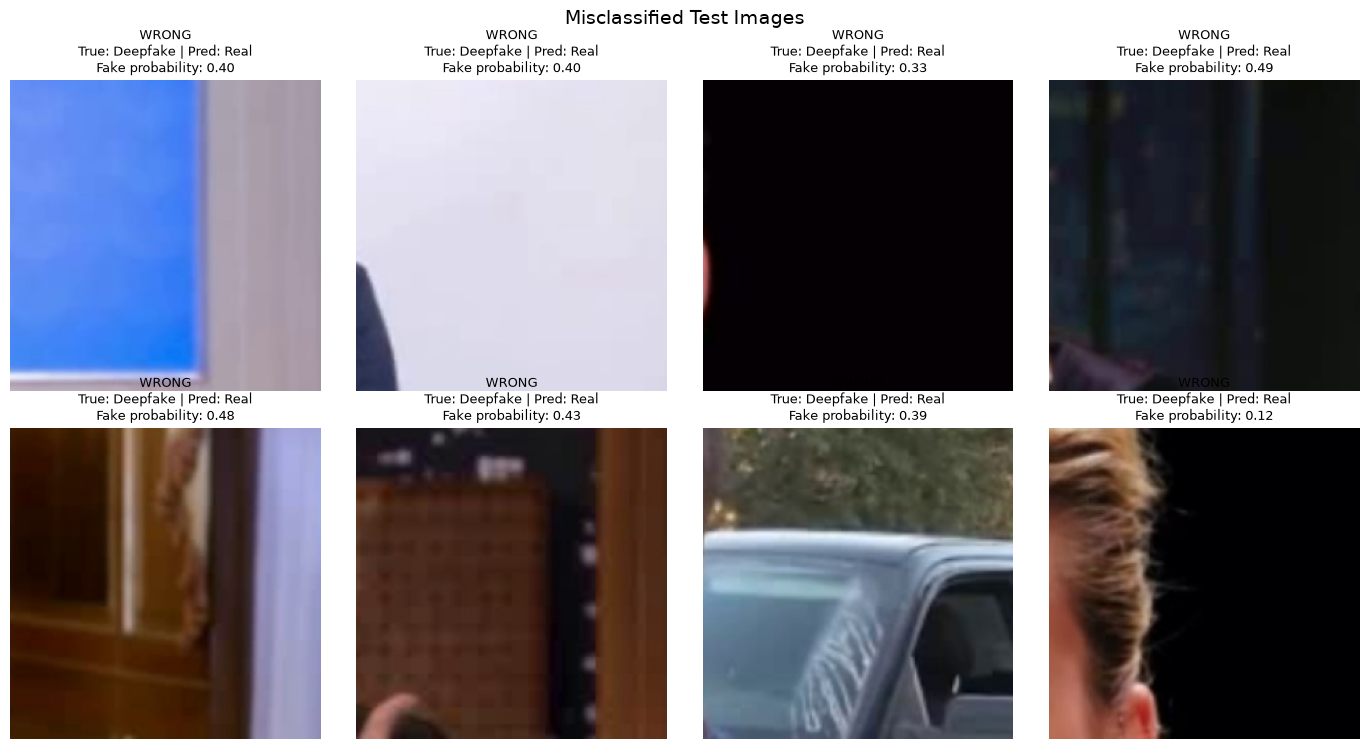


False positives (Real -> Deepfake): 454
False negatives (Deepfake -> Real): 982


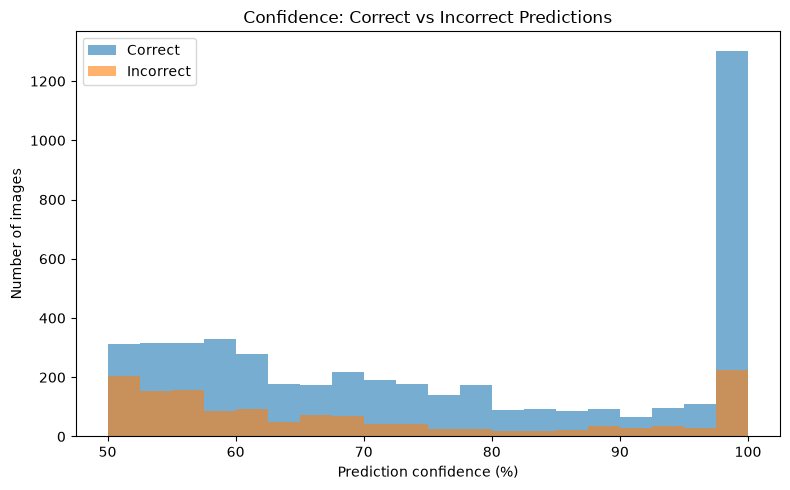


Week 4 Day 2 analysis complete.
Prediction CSV: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\week4_day2_all_predictions.csv
Figures saved in: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\figures


In [16]:

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models, transforms
from PIL import Image
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score

# ============== 1. SETUP ==============
ROOT = Path.cwd().parent
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
MODEL_PATH = ROOT / "models/week4_resnet50.pth"
OUT = ROOT / "results"
FIG = OUT / "figures"

OUT.mkdir(exist_ok=True)
FIG.mkdir(exist_ok=True)

print("Device:", DEVICE)
print("Project:", ROOT)

# ============== 2. LOAD TEST DATA ==============
# Reuse Week 3's existing video-wise test split if available.
if "test_df" not in globals():
    csv_path = OUT / "face_metadata.csv"
    if not csv_path.exists():
        raise FileNotFoundError(
            "test_df available nahi hai aur results/face_metadata.csv nahi mili. "
            "Week 3 notebook mein split banane wala cell run karke phir try karo."
        )
    raise ValueError(
        "Day 1 wala video-wise test_df split is notebook mein available nahi hai. "
        "Week 3 notebook se test_df ko CSV mein save karke load karo, "
        "ya isi notebook mein wahi exact split-generation code run karo."
    )

if not MODEL_PATH.exists():
    raise FileNotFoundError(f"Model file nahi mili: {MODEL_PATH}")

test_data = test_df.reset_index(drop=True).copy()
required = {"face_path", "label"}
if not required.issubset(test_data.columns):
    raise ValueError("test_df mein face_path aur label columns hone chahiye.")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

class TestFaceDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        path = Path(str(row["face_path"]))
        if not path.is_absolute():
            path = ROOT / path

        with Image.open(path) as im:
            img = im.convert("RGB")

        return transform(img), int(row["label"]), str(path)

test_ds = TestFaceDataset(test_data)
loader = DataLoader(test_ds, batch_size=32, shuffle=False, num_workers=0)

# ============== 3. LOAD TRAINED RESNET50 ==============
# weights=None avoids downloading ImageNet weights again.
model = models.resnet50(weights=None)
model.fc = nn.Linear(model.fc.in_features, 1)

state = torch.load(MODEL_PATH, map_location=DEVICE, weights_only=True)
model.load_state_dict(state)
model = model.to(DEVICE)
model.eval()

print("Saved ResNet50 loaded successfully.")

# ============== 4. PREDICT ALL TEST IMAGES ==============
true_labels, probs, paths = [], [], []

with torch.no_grad():
    for images, labels, batch_paths in loader:
        images = images.to(DEVICE)
        logits = model(images).view(-1)
        batch_probs = torch.sigmoid(logits).cpu().numpy()

        true_labels.extend(labels.numpy().tolist())
        probs.extend(batch_probs.tolist())
        paths.extend(batch_paths)

y_true = np.array(true_labels, dtype=int)
y_prob = np.array(probs)
y_pred = (y_prob >= 0.5).astype(int)

results = pd.DataFrame({
    "image_path": paths,
    "true_label": y_true,
    "predicted_label": y_pred,
    "probability_deepfake": y_prob,
    "confidence_percent": np.maximum(y_prob, 1-y_prob) * 100,
    "correct": y_true == y_pred
})

results["true_class"] = results["true_label"].map({0: "Real", 1: "Deepfake"})
results["predicted_class"] = results["predicted_label"].map({0: "Real", 1: "Deepfake"})
results.to_csv(OUT / "week4_day2_all_predictions.csv", index=False)

print("\nTest accuracy:", round(accuracy_score(y_true, y_pred), 4))
print("\nClassification report:")
print(classification_report(
    y_true, y_pred,
    labels=[0, 1],
    target_names=["Real", "Deepfake"],
    zero_division=0
))

# ============== 5. CONFUSION MATRIX ==============
cm = confusion_matrix(y_true, y_pred, labels=[0, 1])

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(cm, cmap="Blues")
fig.colorbar(im, ax=ax)
ax.set_xticks([0, 1], ["Real", "Deepfake"])
ax.set_yticks([0, 1], ["Real", "Deepfake"])
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
ax.set_title("Day 2: ResNet50 Confusion Matrix")

for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black",
                fontsize=13)

plt.tight_layout()
plt.savefig(FIG / "week4_day2_confusion_matrix.png", dpi=180)
plt.show()

# ============== 6. SHOW CORRECT AND WRONG PREDICTIONS ==============
correct = results[results["correct"]].copy()
wrong = results[~results["correct"]].copy()

print(f"\nCorrect predictions: {len(correct)}")
print(f"Incorrect predictions: {len(wrong)}")

def show_examples(frame, title, filename, count=8):
    if frame.empty:
        print("No examples available for:", title)
        return

    # Mix examples rather than displaying only the first few
    display_df = frame.sample(n=min(count, len(frame)), random_state=42)
    n = len(display_df)
    cols = 4
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(14, 3.8 * rows))
    axes = np.array(axes).reshape(-1)

    for ax in axes:
        ax.axis("off")

    for ax, (_, row) in zip(axes, display_df.iterrows()):
        with Image.open(row["image_path"]) as im:
            ax.imshow(im.convert("RGB"))

        status = "CORRECT" if row["correct"] else "WRONG"
        ax.set_title(
            f"{status}\nTrue: {row['true_class']} | Pred: {row['predicted_class']}\n"
            f"Fake probability: {row['probability_deepfake']:.2f}",
            fontsize=9
        )
        ax.axis("off")

    fig.suptitle(title, fontsize=14)
    plt.tight_layout()
    plt.savefig(FIG / filename, dpi=180, bbox_inches="tight")
    plt.show()

show_examples(
    correct, "Correctly Classified Test Images",
    "week4_day2_correct_predictions.png"
)
show_examples(
    wrong, "Misclassified Test Images",
    "week4_day2_wrong_predictions.png"
)

# ============== 7. ERROR ANALYSIS ==============
# False positive: real predicted as deepfake
false_positives = results[
    (results["true_label"] == 0) & (results["predicted_label"] == 1)
]
# False negative: deepfake predicted as real
false_negatives = results[
    (results["true_label"] == 1) & (results["predicted_label"] == 0)
]

print("\nFalse positives (Real -> Deepfake):", len(false_positives))
print("False negatives (Deepfake -> Real):", len(false_negatives))

false_positives.to_csv(OUT / "week4_day2_false_positives.csv", index=False)
false_negatives.to_csv(OUT / "week4_day2_false_negatives.csv", index=False)

# Confidence distribution graph
plt.figure(figsize=(8, 5))
plt.hist(
    results.loc[results["correct"], "confidence_percent"],
    bins=20, alpha=0.6, label="Correct"
)
plt.hist(
    results.loc[~results["correct"], "confidence_percent"],
    bins=20, alpha=0.6, label="Incorrect"
)
plt.xlabel("Prediction confidence (%)")
plt.ylabel("Number of images")
plt.title("Confidence: Correct vs Incorrect Predictions")
plt.legend()
plt.tight_layout()
plt.savefig(FIG / "week4_day2_confidence_analysis.png", dpi=180)
plt.show()

print("\nWeek 4 Day 2 analysis complete.")
print("Prediction CSV:", OUT / "week4_day2_all_predictions.csv")
print("Figures saved in:", FIG)


         evaluation  accuracy  precision_fake  recall_fake  f1_fake  recall_real  number_of_images
Held-out test split    0.7673          0.9037       0.8126   0.8557       0.5118              6170


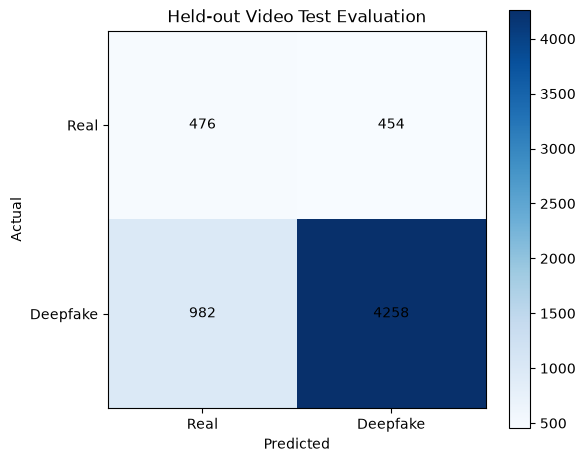

Note: Ye held-out test split evaluation hai, external-dataset test nahi.
Metrics saved: c:\Users\HIMANSHU\Desktop\minor project 1\Minor-Project\results\week4_day3_generalization_metrics.csv


In [17]:

from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

ROOT = Path.cwd().parent
OUT = ROOT / "results"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

pred_path = OUT / "week4_day2_all_predictions.csv"
if not pred_path.exists():
    raise FileNotFoundError(
        "Day 2 prediction CSV nahi mili. Pehle Day 2 ka code run karo."
    )

df = pd.read_csv(pred_path)
required = {"true_label", "predicted_label"}
if not required.issubset(df.columns):
    raise ValueError("Prediction CSV mein true_label/predicted_label missing hain.")

y_true = df["true_label"].astype(int)
y_pred = df["predicted_label"].astype(int)

metrics = pd.DataFrame([{
    "evaluation": "Held-out test split",
    "accuracy": accuracy_score(y_true, y_pred),
    "precision_fake": precision_score(y_true, y_pred, zero_division=0),
    "recall_fake": recall_score(y_true, y_pred, zero_division=0),
    "f1_fake": f1_score(y_true, y_pred, zero_division=0),
    "recall_real": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
    "number_of_images": len(df)
}])

metrics.to_csv(OUT / "week4_day3_generalization_metrics.csv", index=False)
print(metrics.round(4).to_string(index=False))

cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
plt.figure(figsize=(6, 5))
plt.imshow(cm, cmap="Blues")
plt.colorbar()
plt.xticks([0, 1], ["Real", "Deepfake"])
plt.yticks([0, 1], ["Real", "Deepfake"])
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Held-out Video Test Evaluation")

for i in range(2):
    for j in range(2):
        plt.text(j, i, str(cm[i, j]), ha="center", va="center")

plt.tight_layout()
plt.savefig(FIG / "week4_day3_generalization_confusion_matrix.png", dpi=180)
plt.show()

print("Note: Ye held-out test split evaluation hai, external-dataset test nahi.")
print("Metrics saved:", OUT / "week4_day3_generalization_metrics.csv")


     model  accuracy  precision_fake  recall_fake  f1_fake  recall_real
Custom CNN    0.7365          0.8651       0.8172   0.8404       0.2817
  ResNet50    0.7673          0.9037       0.8126   0.8557       0.5118


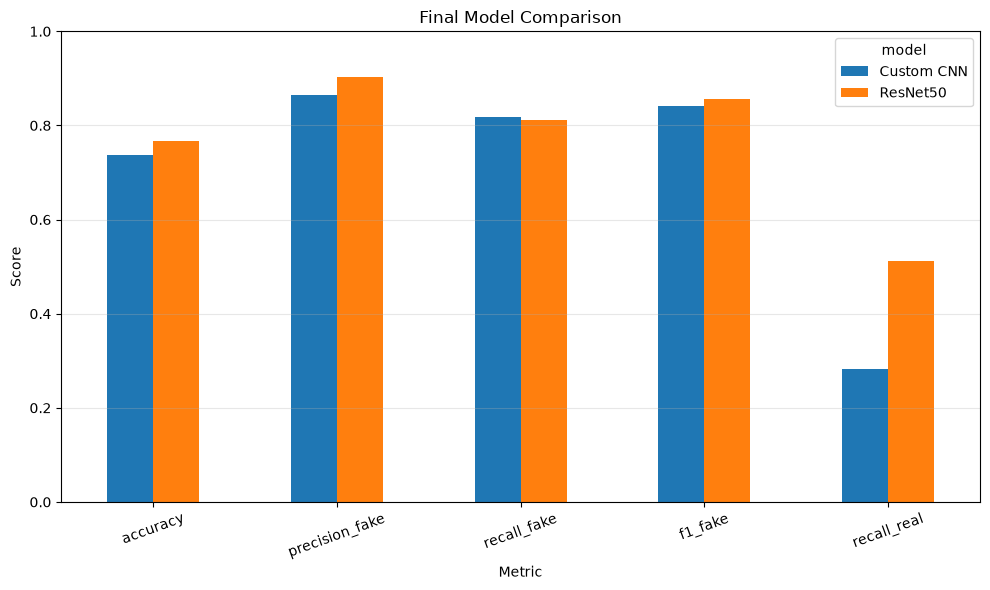

Final comparison saved.


In [18]:

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
OUT = ROOT / "results"
FIG = OUT / "figures"
FIG.mkdir(parents=True, exist_ok=True)

files = {
    "Custom CNN": OUT / "week3_custom_cnn_metrics.csv",
    "ResNet50": OUT / "week4_resnet50_metrics.csv"
}

metric_cols = [
    "accuracy", "precision_fake", "recall_fake",
    "f1_fake", "recall_real"
]

rows = []
for model_name, path in files.items():
    if not path.exists():
        print("Skipped, file missing:", path)
        continue

    data = pd.read_csv(path)
    row = {"model": model_name}

    for col in metric_cols:
        row[col] = data.iloc[0][col] if col in data.columns else None

    rows.append(row)

if not rows:
    raise FileNotFoundError("Koi model metrics CSV nahi mili.")

comparison = pd.DataFrame(rows)
comparison.to_csv(OUT / "week4_day4_final_comparison.csv", index=False)
print(comparison.round(4).to_string(index=False))

available_metrics = [c for c in metric_cols if comparison[c].notna().any()]
plot_data = comparison.set_index("model")[available_metrics]

ax = plot_data.T.plot(kind="bar", figsize=(10, 6), ylim=(0, 1))
ax.set_title("Final Model Comparison")
ax.set_ylabel("Score")
ax.set_xlabel("Metric")
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig(FIG / "week4_day4_final_comparison.png", dpi=180)
plt.show()

print("Final comparison saved.")
